In [1]:
# imports
%matplotlib widget
import ipywidgets as widgets
import matplotlib.pyplot as plt
import numpy as np
import scipy.integrate as spintg
import scipy.interpolate as spintp

In [2]:
def calculate_position(theta_l, theta_r, d_x, d_y, r_m):
    x = ((r_m * (theta_l + theta_r) - d_y)) / 2
    y = ((r_m * (theta_l - theta_r) + d_y)) / 2

    return x, y

interactive(children=(FloatSlider(value=200.0, description='theta_l', max=400.0), FloatSlider(value=200.0, des…

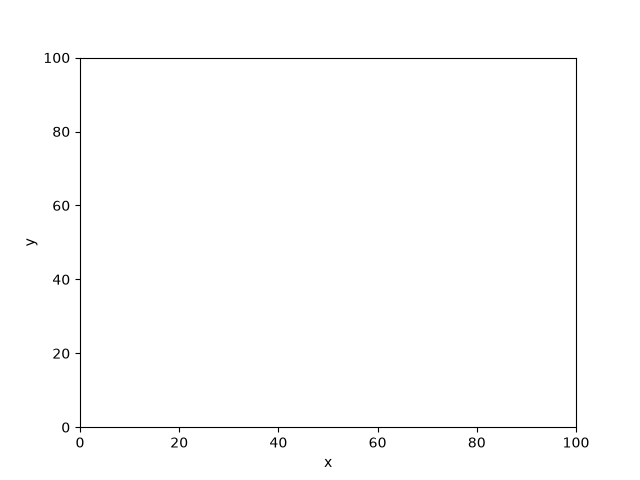

In [3]:
# Here I define my static variables. They can be changed but are chosen for convenience in plotting
# I am trying to keep the plots as general and customizable as possible!
d_x = 100.0
d_y = 100.0
theta_l_init = 200.0
theta_r_init = 200.0
r_m = 1.0

x, y = calculate_position(theta_l_init, theta_r_init, d_x, d_y, r_m)

fig, ax = plt.subplots()

ax.set(xlim=(0, d_x), ylim=(0, d_y))
ax.set_xlabel("x")
ax.set_ylabel("y")

plot = ax.scatter(x, y) # Create INITIAL scatter plot

@widgets.interact(
    theta_l=widgets.FloatSlider(min=0.0, max=400.0, value=200.0, step=0.1),
    theta_r=widgets.FloatSlider(min=0.0, max=400.0, value=200.0, step=0.1)
)
def update_position(theta_l, theta_r):
    
    x, y = calculate_position(theta_l, theta_r, d_x, d_y, r_m)

    print(x, y)

    plot.set_offsets([[x, y]])

    fig.canvas.draw_idle()

In [4]:
K_M = 1.0
m = 1.0
J_m = 1.0
L_m = 1.0
R_m = 1.0
def C_m(K_M, m, J_m, r_m):
    return (K_M * r_m) / (r_m * r_m * m + 2 * J_m)
C_m = C_m(K_M, m, J_m, r_m)

A = np.array([
    [0, 1, 0, 0, 0, 0],                             #position x
    [0, 0, C_m, 0, 0, 0],                           #velocity x
    [0, -2 * K_M / (r_m * L_m), -R_m / L_m, 0, 0, 0], #current x
    [0, 0, 0, 0, 1, 0],                             # position y
    [0, 0, 0, 0, 0, C_m],                           # velocity y
    [0, 0, 0, 0, -2 * K_M / (r_m * L_m), -R_m / L_m]  #current y
])

B = np.array([
    [0, 0],
    [0, 0],
    [1/L_m, 0],
    [0, 0],
    [0, 0],
    [0, 1/L_m]
])


C = np.array([
    [1, 0, 0, 0, 0, 0],
    [0, 0, 0, 1, 0, 0]
])

CAAB = C @ A @ A @ B
CAAA = C @ A @ A @ A

print(CAAB)
print(CAAA)

[[0.33333333 0.        ]
 [0.         0.33333333]]
[[ 0.         -0.66666667 -0.33333333  0.          0.          0.        ]
 [ 0.          0.          0.          0.         -0.66666667 -0.33333333]]


In [5]:
a = 40
b = 30
omega = 12
delta = np.pi / 2
t_start = 0
t_fin = 10

t = np.linspace(t_start, t_fin, 2000) # timepoints
dt = t[1] - t[0]
# My desired trajectory, an ellipse
y = np.array([
    a * np.sin(omega * t + delta),
    b * np.sin(t)
])

print(y.shape)

dydt = np.array([
    a * omega * np.cos(omega * t + delta),
    b * np.cos(t)
])
dydt_2 = np.array([
    -a * omega**2 * np.sin(omega * t + delta),
    -b * np.sin(t)
])
dydt_3 = np.array([
    -a * omega**3 * np.cos(omega * t + delta),
    -b * np.cos(t)
])

x = np.array([
    a * np.sin(omega * t + delta),
    dydt[0],
    (1/C_m) * dydt_2[0], #current calculated in terms of trajectory
    b * np.sin(t),
    dydt[1],
    (1/C_m) * dydt_2[1], #current calculated in terms of trajectory
])
print(x.shape)
CAAB_inv = np.linalg.pinv(CAAB)

u = CAAB_inv @ (dydt_3 - CAAA @ x)
print(u[:, 0])

(2, 2000)
(6, 2000)
[-17280.    -30.]


In [6]:
# Time to see if it works!
x0 = x[:, 0]
print(x0)
print(y[:, 0])

# ODE solver needs a function that can return a value for any time, 
# even not belonging of my linspace t
u_interpolate = spintp.interp1d(t, u)

def system_dynamics(t, state):
    u_now = u_interpolate(t)
    return A @ state + B @ u_now

solution = spintg.solve_ivp(system_dynamics, (t_start, t_fin), x0, t_eval=t, method='RK45')

y_calculated = C @ solution.y # This is my trajectory

[ 4.00000000e+01  2.93915232e-14 -1.72800000e+04  0.00000000e+00
  3.00000000e+01 -0.00000000e+00]
[40.  0.]


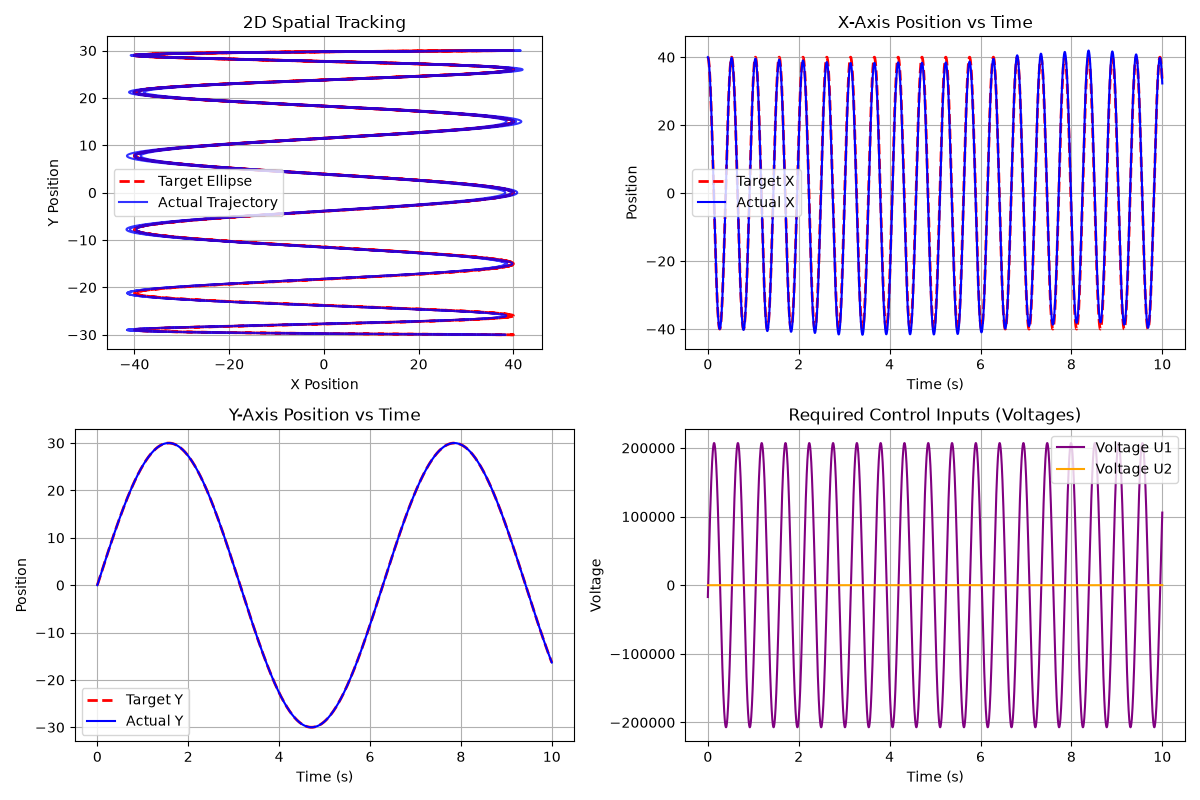

In [7]:
# For this cell I used Gemini to help make the plots understandable

fig, axs = plt.subplots(2, 2, figsize=(12, 8))

# 1. Top-Left: 2D Ellipse Tracking (Target vs Actual)
axs[0, 0].plot(y[0], y[1], 'r--', label='Target Ellipse', linewidth=2)
axs[0, 0].plot(y_calculated[0], y_calculated[1], 'b-', label='Actual Trajectory', alpha=0.8)
axs[0, 0].set_title('2D Spatial Tracking')
axs[0, 0].set_xlabel('X Position')
axs[0, 0].set_ylabel('Y Position')
axs[0, 0].legend()
axs[0, 0].grid(True)
axs[0, 0].set_aspect('equal') # Keeps the ellipse from distorting

# 2. Top-Right: X-Axis Tracking Over Time
axs[0, 1].plot(t, y[0], 'r--', label='Target X', linewidth=2)
axs[0, 1].plot(t, y_calculated[0], 'b-', label='Actual X')
axs[0, 1].set_title('X-Axis Position vs Time')
axs[0, 1].set_xlabel('Time (s)')
axs[0, 1].set_ylabel('Position')
axs[0, 1].legend()
axs[0, 1].grid(True)

# 3. Bottom-Left: Y-Axis Tracking Over Time
axs[1, 0].plot(t, y[1], 'r--', label='Target Y', linewidth=2)
axs[1, 0].plot(t, y_calculated[1], 'b-', label='Actual Y')
axs[1, 0].set_title('Y-Axis Position vs Time')
axs[1, 0].set_xlabel('Time (s)')
axs[1, 0].set_ylabel('Position')
axs[1, 0].legend()
axs[1, 0].grid(True)

axs[1, 1].plot(t, u[0], label='Voltage U1', color='purple')
axs[1, 1].plot(t, u[1], label='Voltage U2', color='orange')
axs[1, 1].set_title('Required Control Inputs (Voltages)')
axs[1, 1].set_xlabel('Time (s)')
axs[1, 1].set_ylabel('Voltage')
axs[1, 1].legend()
axs[1, 1].grid(True)

plt.tight_layout()
plt.show()